# 6. Explicaciones de la variante

Comparamos la variante global–regional con las tres referencias del cuaderno 03 en las mismas imágenes de validación. Primero medimos la localización de los mapas y el efecto de ocultar las zonas que destacan. Después revisamos casos concretos y probamos cómo cambian los resultados al variar el reemplazo o los pesos del modelo.

In [1]:
import gc
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from PIL import Image

from photovoltaic_xai import CLASS_NAMES, MODEL_NAMES
from photovoltaic_xai.dataset import letterbox
from photovoltaic_xai.models import save_json
from photovoltaic_xai.notebook_support import decimal_label, figure_style, project_root, show_figure
from photovoltaic_xai.preparation import load_preparation
from photovoltaic_xai.variant import file_hash, load_variant, load_variant_manifest
from photovoltaic_xai.variant_xai import (
    blur_views,
    image_adapter,
    randomized_variant,
    read_xai_result,
    same_xai_inputs,
    variant_cam,
    variant_xai_key,
)
from photovoltaic_xai.xai import (
    curve_rows,
    evaluate_xai_image,
    localization_metrics,
    pair_random_curves,
    perturbation_curve,
)

## Muestra y resultados de partida

Cargamos la configuración de la variante del cuaderno 04. Del cuaderno 03 recuperamos la selección de 140 imágenes de validación, la submuestra de 16 imágenes para los controles y el banco común de 4000 máscaras RISE.

In [2]:
PROJECT_ROOT = project_root()
VARIANT_DIR = PROJECT_ROOT / "outputs/variant_reference_global"
XAI_DIR = PROJECT_ROOT / "outputs/final_evaluation_reference_global/xai"
REFERENCE_XAI_DIR = PROJECT_ROOT / "outputs/xai/pvel6-eda-v1"
DIAGNOSTIC_DIR = PROJECT_ROOT / "outputs/refinement/validation_diagnostics"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MASK_BATCH_SIZE = 16
torch.set_num_threads(4)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
prepared = load_preparation(PROJECT_ROOT)
manifest_path = VARIANT_DIR / "manifest.json"
manifest = load_variant_manifest(manifest_path, prepared, root=PROJECT_ROOT)
selection = json.loads((REFERENCE_XAI_DIR / "evaluation_val.json").read_text())
control_selection = json.loads((DIAGNOSTIC_DIR / "convnext_tiny/inputs.json").read_text())
if selection["data_fingerprint"] != prepared["data_fingerprint"] or selection["split"] != "val":
    raise ValueError("La selección XAI debe pertenecer a esta partición de validación")
by_id = {record["id"]: record for record in prepared["records"] if record["split"] == "val"}
assert len(set(selection["ids"])) == len(selection["ids"])
records = [by_id[identifier] for identifier in selection["ids"]]
control_ids = control_selection["ids"]
assert len(control_ids) == len(set(control_ids)) and set(control_ids) <= set(selection["ids"])
bank_path = REFERENCE_XAI_DIR / "rise_bank_val.pt"
bank = torch.load(bank_path, map_location="cpu", weights_only=True)
assert bank["config"] == selection["rise"] and bank["config"]["n_masks"] == 4000
weights = {name: digest for name, digest in manifest["sha256"].items() if name.endswith(".pt")}
identity = {
    "selected": {
        "data_fingerprint": prepared["data_fingerprint"],
        "class_names": list(CLASS_NAMES),
        "normalization": prepared["normalization"],
        "weights": weights,
        "thresholds": manifest["thresholds"],
        "geometry": manifest["geometry"],
    },
    "ids": selection["ids"],
    "bank_sha256": file_hash(bank_path),
    "config": selection["config"],
    "control_selection": {"ids": control_ids, "config": control_selection["config"]},
    "secondary_baseline": "native Pillow GaussianBlur radius=12*native_long_side/512 before both views",
}
thresholds = np.asarray(identity["selected"]["thresholds"])
inputs_key = variant_xai_key(identity)
XAI_DIR.mkdir(parents=True, exist_ok=True)
print(f"Imágenes de validación: {len(records)}. Imágenes para los controles: {len(control_ids)}.")

Imágenes de validación: 140. Imágenes para los controles: 16.


## Mapas y eliminación

Calculamos los mapas Grad-CAM, Layer-CAM y RISE. Los mapas CAM reúnen las aportaciones de la vista global y los recortes. En la prueba de eliminación ocultamos las mismas zonas en ambas vistas y comparamos la probabilidad al seguir el mapa o al borrar al azar.

In [3]:
summary_path = XAI_DIR / "summary.json"
previous_summary = json.loads(summary_path.read_text()) if summary_path.is_file() else {}
saved_identity = previous_summary.get("identity")
if saved_identity is not None and not same_xai_inputs(saved_identity, identity):
    raise ValueError("Saved XAI inputs differ; existing results are preserved")
committed_aggregates = (
    saved_identity is not None
    and previous_summary.get("status") == "complete"
    and previous_summary.get("images") == len(records)
    and previous_summary.get("control_images") == len(control_ids)
)

model = None
spatial_rows, curve_rows_saved = [], []
new_images = 0
for index, record in enumerate(records, start=1):
    path = XAI_DIR / f"{record['id']}.json"
    report = read_xai_result(path, identity, maps=True, verify_map=not committed_aggregates)
    if report is None:
        if model is None:
            model = load_variant(manifest_path, device=DEVICE, root=PROJECT_ROOT, manifest=manifest)
        adapter, reference = image_adapter(PROJECT_ROOT, prepared, model, record, DEVICE)
        rows, image_curves, maps = evaluate_xai_image(
            "variant",
            adapter,
            adapter.mask_image,
            reference,
            adapter.valid_mask,
            thresholds,
            bank,
            lambda c, method: variant_cam(adapter, c, method=method),
            batch_size=MASK_BATCH_SIZE,
            save_maps=True,
        )
        temporary = path.with_suffix(".npz.tmp")
        maps_path = path.with_suffix(".npz")
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, **maps)
        temporary.replace(maps_path)
        report = {
            "inputs_key": inputs_key,
            "spatial": rows,
            "curves": image_curves,
            "shared_random": True,
            "maps_sha256": file_hash(maps_path),
        }
        save_json(path, report)
        new_images += 1
        if index % 10 == 0:
            print(f"Mapas: {index}/{len(records)} imágenes", flush=True)
        del adapter, reference, maps
    spatial_rows.extend(report["spatial"])
    curve_rows_saved.extend(report["curves"])

location = pd.DataFrame(spatial_rows)
curves = pd.DataFrame(pair_random_curves(curve_rows_saved))
expected_targets = sum(sum(record["labels"]) or 6 for record in records)
assert len(location) == expected_targets * 3 and len(curves) == expected_targets * 126
del model
print(f"Mapas listos: {len(records)} imágenes ({new_images} calculadas en esta ejecución).")

Mapas: 10/140 imágenes
Mapas: 20/140 imágenes
Mapas: 30/140 imágenes
Mapas: 40/140 imágenes
Mapas: 50/140 imágenes
Mapas: 60/140 imágenes
Mapas: 70/140 imágenes
Mapas: 80/140 imágenes
Mapas: 90/140 imágenes
Mapas: 100/140 imágenes
Mapas: 110/140 imágenes
Mapas: 120/140 imágenes
Mapas: 130/140 imágenes
Mapas: 140/140 imágenes
Mapas listos: 140 imágenes (140 calculadas en esta ejecución).


## Controles

En 12 imágenes con defectos y 4 sanas, repetimos la prueba de eliminación con Grad-CAM y Layer-CAM usando una versión desenfocada como reemplazo. En la misma submuestra, recalculamos los mapas tras reinicializar las salidas y los extractores por separado con las semillas 43 y 44.

In [4]:
directory = XAI_DIR
model = None
control_rows, blur_curves = [], []
for identifier in control_ids:
    record = by_id[identifier]
    path = directory / "controls" / f"baseline_{identifier}.json"
    saved = read_xai_result(path, identity)
    if saved is None:
        if model is None:
            model = load_variant(manifest_path, device=DEVICE, root=PROJECT_ROOT, manifest=manifest)
        adapter, reference = image_adapter(PROJECT_ROOT, prepared, model, record, DEVICE)
        if read_xai_result(directory / f"{identifier}.json", identity, maps=True) is None:
            raise ValueError(f"Faltan mapas para {identifier}")
        original_maps = np.load(directory / f"{identifier}.npz", allow_pickle=False)
        blurred = adapter.with_baseline(*blur_views(PROJECT_ROOT, prepared, record, DEVICE))
        targets = torch.nonzero(reference["labels"]).flatten().tolist() or list(range(6))
        local_curves = []
        for c in targets:
            random = perturbation_curve(
                blurred,
                blurred.mask_image,
                c,
                torch.from_numpy(original_maps[f"gradcam_{c}"]).to(DEVICE),
                valid_mask=blurred.valid_mask,
                random_order=True,
            )
            for method in ("gradcam", "layercam"):
                saliency = torch.from_numpy(original_maps[f"{method}_{c}"]).to(DEVICE)
                item = {
                    "run": "variant",
                    "id": identifier,
                    "class": CLASS_NAMES[c],
                    "healthy": not any(record["labels"]),
                }
                curve = perturbation_curve(
                    blurred, blurred.mask_image, c, saliency, valid_mask=blurred.valid_mask
                )
                local_curves.extend(curve_rows(item, method, curve, baseline="native_blur"))
                local_curves.extend(
                    curve_rows(item, method, random, random=True, baseline="native_blur")
                )
        saved = {"inputs_key": inputs_key, "curves": local_curves}
        save_json(path, saved)
        original_maps.close()
    blur_curves.extend(saved["curves"])
for seed in (43, 44):
    for scope in ("readouts", "encoders"):
        control = None
        for identifier in control_ids:
            path = directory / "controls" / f"{scope}_{seed}_{identifier}.json"
            saved = read_xai_result(path, identity)
            if saved is None:
                if model is None:
                    model = load_variant(
                        manifest_path, device=DEVICE, root=PROJECT_ROOT, manifest=manifest
                    )
                if control is None:
                    control = randomized_variant(model, scope=scope, seed=seed).to(DEVICE)
                adapter, reference = image_adapter(
                    PROJECT_ROOT, prepared, control, by_id[identifier], DEVICE
                )
                if read_xai_result(directory / f"{identifier}.json", identity, maps=True) is None:
                    raise ValueError(f"Faltan mapas para {identifier}")
                original_maps = np.load(directory / f"{identifier}.npz", allow_pickle=False)
                targets = torch.nonzero(reference["labels"]).flatten().tolist() or list(range(6))
                with torch.inference_mode():
                    logits = adapter(adapter.mask_image[None])[0].cpu().numpy()
                local_rows = []
                for c in targets:
                    for method in ("gradcam", "layercam"):
                        changed = variant_cam(adapter, c, method=method)["fused"]
                        valid = adapter.valid_mask.cpu().numpy()
                        original = original_maps[f"{method}_{c}"][valid]
                        values = changed.cpu().numpy()[valid]
                        correlation = (
                            float(np.corrcoef(original, values)[0, 1])
                            if np.std(original) > 0 and np.std(values) > 0
                            else None
                        )
                        local_rows.append(
                            {
                                "run": "variant",
                                "id": identifier,
                                "class": CLASS_NAMES[c],
                                "healthy": not any(by_id[identifier]["labels"]),
                                "method": method,
                                "scope": scope,
                                "seed": seed,
                                "logit": float(logits[c]),
                                "probability": float(torch.tensor(logits[c]).sigmoid()),
                                "correlation": correlation,
                                **localization_metrics(
                                    changed,
                                    reference["masks"][c],
                                    valid_mask=adapter.valid_mask,
                                ),
                            }
                        )
                original_maps.close()
                saved = {"inputs_key": inputs_key, "rows": local_rows}
                save_json(path, saved)
            control_rows.extend(saved["rows"])
        del control
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

expected_control_targets = sum(sum(by_id[i]["labels"]) or 6 for i in control_ids)
assert len(control_rows) == expected_control_targets * 8
assert len(blur_curves) == expected_control_targets * 84
if not committed_aggregates:
    save_json(
        summary_path,
        {
            "identity": identity,
            "status": "complete",
            "images": len(records),
            "expected_images": len(records),
            "control_images": len(control_ids),
            "control_seeds": [43, 44],
        },
    )
controls = pd.DataFrame(control_rows)
del model
gc.collect()

33

## Comparación con las referencias

Las dos tablas reúnen los mismos 161 pares de imagen y defecto anotado. Una imagen con varios defectos aporta un par por cada etiqueta, tanto si el modelo la detecta como si la omite.

### Localización de los defectos

Pointing Game mide qué proporción de los puntos de máxima intensidad del mapa cae dentro de las cajas. La energía corregida mide cuánto peso concentra el mapa en las cajas en relación con su área. `count` recoge cuántos pares contribuyen a cada media.

In [5]:
reference_location = pd.read_csv(REFERENCE_XAI_DIR / "localization_val.csv")
all_location = pd.concat(
    [reference_location, location],
    ignore_index=True,
)
spatial_comparison = (
    all_location.loc[~all_location.healthy]
    .groupby(["run", "method"])[["pointing_game", "energy_corrected"]]
    .agg(["mean", "count"])
)
display(spatial_comparison)

pointing_game       energy_corrected      
                                  mean count             mean count
run             method                                             
convnext_tiny   gradcam       0.461180   161         0.015593   161
                layercam      0.490683   161         0.052306   161
                rise          0.670807   161         0.000739   161
efficientnet_b0 gradcam       0.370342   161        -0.065643   161
                layercam      0.636646   161        -0.198911   161
                rise          0.639752   161         0.000458   161
swin_t          gradcam       0.503591   161         0.045395   161
                layercam      0.708075   161         0.060458   161
                rise          0.652174   161         0.000607   161
variant         gradcam       0.547360   161         0.044727   161
                layercam      0.552795   161         0.073374   161
                rise          0.658385   161         0.000658   161

Con Grad-CAM y Layer-CAM, la variante mejora ambas métricas frente a ConvNeXt. Swin con Layer-CAM obtiene el mayor Pointing Game de la tabla (0,708).

### Efecto de la eliminación

Restamos al área bajo la curva guiada la del orden aleatorio y promediamos esa diferencia (ΔAUC) por modelo y método. Un valor negativo indica que la probabilidad se mantiene más baja, en promedio, al ocultar las zonas destacadas por el mapa.

In [6]:
reference_curves = pd.DataFrame(
    pair_random_curves(pd.read_csv(REFERENCE_XAI_DIR / "perturbations_val.csv").to_dict("records"))
)
all_curves = pd.concat(
    [reference_curves, curves],
    ignore_index=True,
)
# The area is repeated at each fraction; retain one area per original pair/order.
area_by_pair = (
    all_curves.groupby(
        ["run", "id", "class", "method", "healthy", "random_order"],
        dropna=False,
    )["auc_probability"]
    .first()
    .unstack("random_order")
)
area_by_pair["delta_auc"] = area_by_pair[False] - area_by_pair[True]
deletion_comparison = (
    area_by_pair.reset_index()
    .query("healthy == False")
    .groupby(["run", "method"])["delta_auc"]
    .agg(["mean", "count"])
)
display(deletion_comparison)

mean  count
run             method                   
convnext_tiny   gradcam  -0.214859    161
                layercam -0.209375    161
                rise     -0.120022    161
efficientnet_b0 gradcam   0.385791    161
                layercam  0.316977    161
                rise      0.417404    161
swin_t          gradcam  -0.177151    161
                layercam -0.160562    161
                rise     -0.082036    161
variant         gradcam  -0.179048    161
                layercam -0.192538    161
                rise     -0.136656    161

ConvNeXt obtiene el ΔAUC más bajo con ambos métodos CAM. Con RISE, el menor ΔAUC es el de la variante (−0,137 frente a −0,120 en ConvNeXt).

## Curvas de eliminación y ejemplos

Cargamos los mapas, las predicciones y los controles de las referencias para preparar las figuras. Comprobamos que los archivos corresponden a los pesos guardados de cada referencia y a la misma submuestra de control.

In [7]:
model_names = [*MODEL_NAMES, "variant"]
model_titles = ["EfficientNet-B0", "ConvNeXt-Tiny", "Swin-Tiny", "Variante"]
methods = ["gradcam", "layercam", "rise"]
method_titles = ["Grad-CAM", "Layer-CAM", "RISE"]
reference_runs, reference_maps, reference_probabilities = {}, {}, {}
reference_perturbations, reference_controls = {}, {}
for name in MODEL_NAMES:
    directory = DIAGNOSTIC_DIR / name
    inputs = json.loads((directory / "inputs.json").read_text())
    assert inputs["data_fingerprint"] == prepared["data_fingerprint"]
    assert inputs["config"] == control_selection["config"]
    assert inputs["ids"] == control_ids
    assert inputs["checkpoint_sha256"] == file_hash(
        PROJECT_ROOT / "outputs/experiments" / name / "best.pt"
    )
    reference_runs[name] = json.loads(
        (PROJECT_ROOT / "outputs/experiments" / name / "run.json").read_text()
    )
    reference_maps[name] = torch.load(directory / "maps.pt", map_location="cpu", weights_only=True)
    reference_probabilities[name] = pd.read_csv(directory / "reference_predictions.csv").set_index(
        ["id", "class"]
    )
    reference_perturbations[name] = pd.read_csv(directory / "perturbations.csv")
    reference_controls[name] = pd.read_csv(directory / "controls.csv")
positive_pairs = {
    (identifier, CLASS_NAMES[c])
    for identifier in control_ids
    for c, present in enumerate(by_id[identifier]["labels"])
    if present
}
assert len(positive_pairs) == 16 and len({identifier for identifier, _ in positive_pairs}) == 12
variant_blur = pd.DataFrame(blur_curves)
plt.rcParams.update(figure_style(11))

### Curvas de eliminación guiada y aleatoria

Cada panel muestra, para un método, la probabilidad media al seguir el mapa menos la del orden aleatorio. El eje horizontal indica el porcentaje de píxeles válidos que sustituimos por la media de entrenamiento.

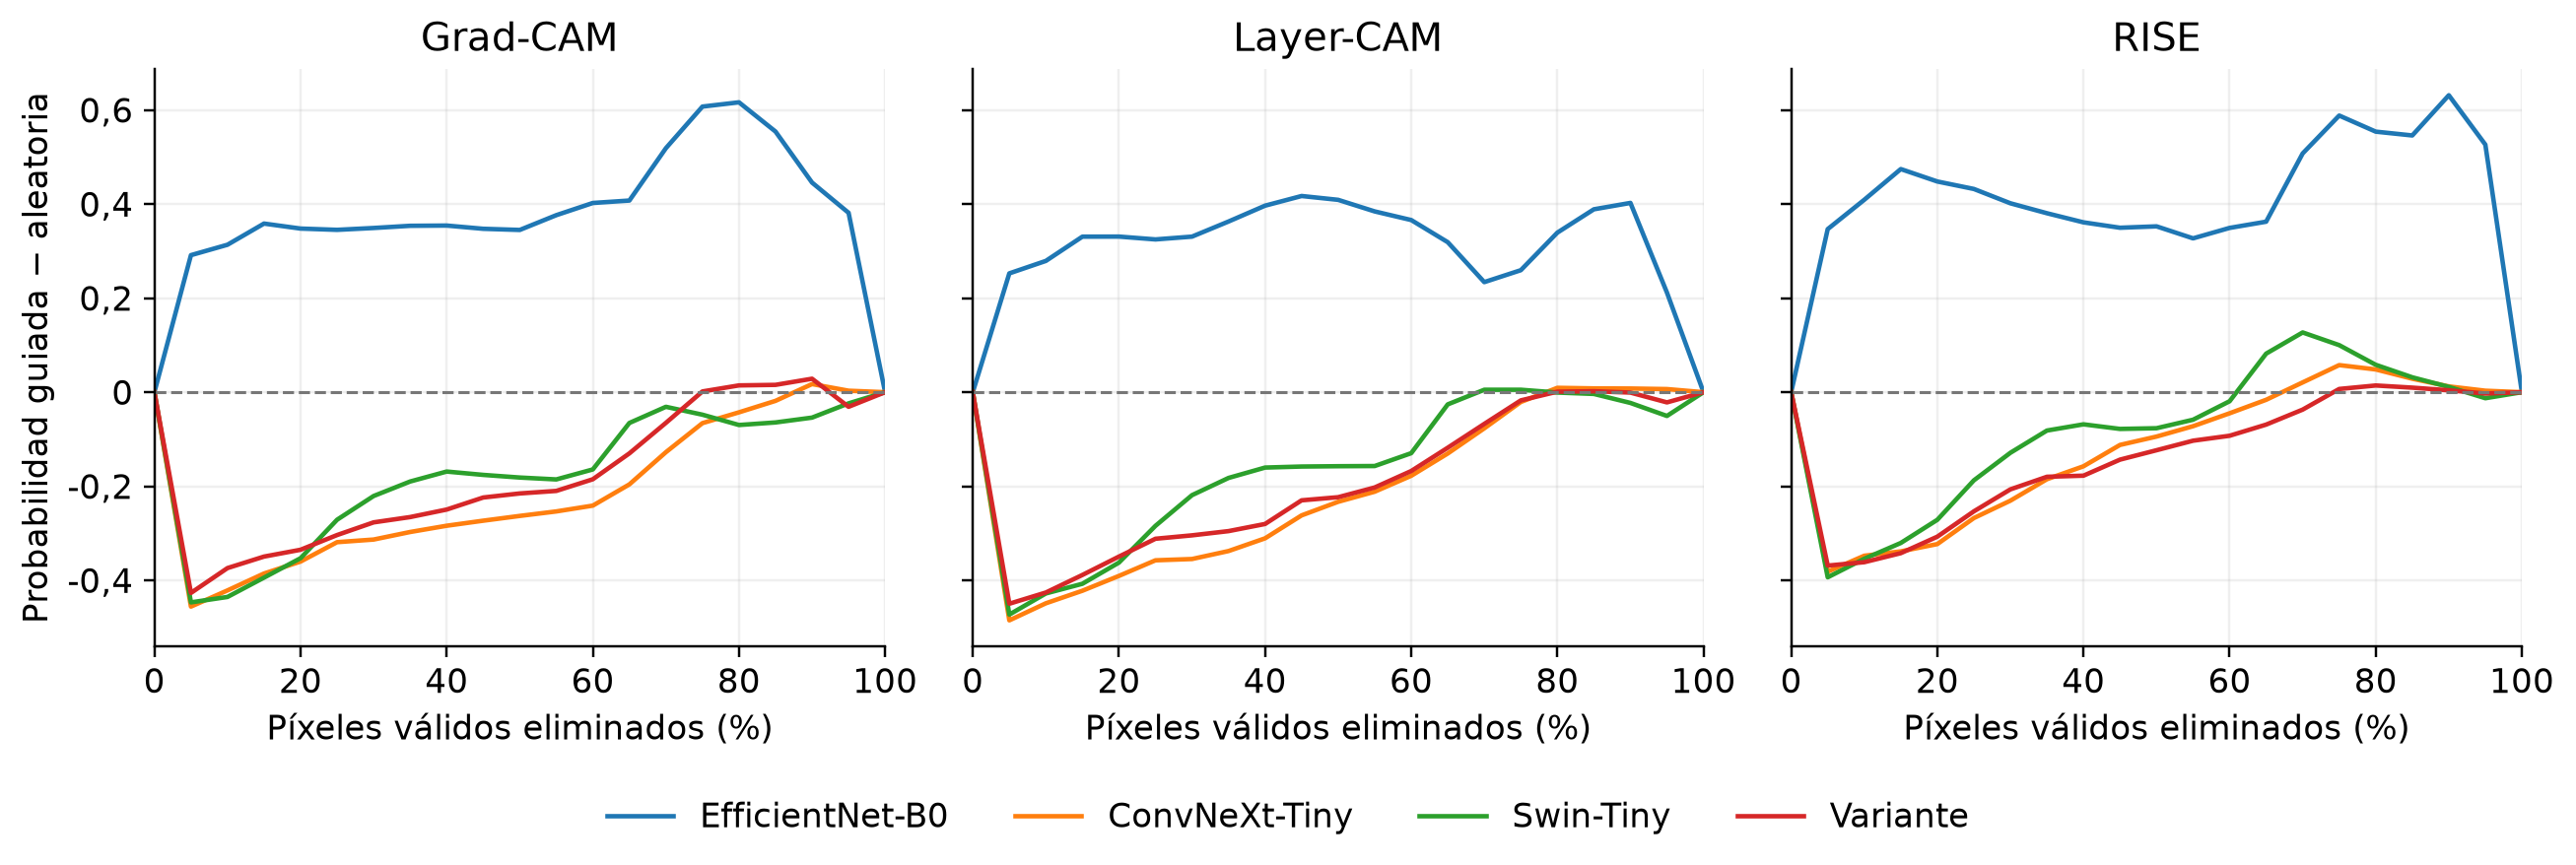

In [8]:
# Guided minus random probability on the same 161 positive pairs in every model.
positive_curves = all_curves.loc[~all_curves.healthy]
paired_probabilities = (
    positive_curves.groupby(["run", "id", "class", "method", "fraction", "random_order"])
    .masked_probability.first()
    .unstack("random_order")
)
assert paired_probabilities.notna().all().all()
paired_probabilities["delta"] = paired_probabilities[False] - paired_probabilities[True]
deleted_means = (
    paired_probabilities.reset_index()
    .groupby(["run", "method", "fraction"])
    .delta.agg(["mean", "count"])
    .reset_index()
)
assert deleted_means["count"].eq(161).all()
mean_areas = (
    area_by_pair.reset_index().query("healthy == False").groupby(["run", "method"]).delta_auc.mean()
)
for (name, method), frame in deleted_means.groupby(["run", "method"]):
    frame = frame.sort_values("fraction")
    assert np.isclose(
        np.trapezoid(frame["mean"], frame.fraction), mean_areas.loc[name, method], atol=1e-6
    )
fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), sharex=True, sharey=True)
for axis, method, title in zip(axes, methods, method_titles, strict=True):
    for name, label in zip(model_names, model_titles, strict=True):
        frame = deleted_means.loc[(deleted_means.run == name) & (deleted_means.method == method)]
        axis.plot(100 * frame.fraction, frame["mean"], label=label)
    axis.axhline(0, color="#777777", linestyle="--", linewidth=1)
    axis.set(title=title, xlabel="Píxeles válidos eliminados (%)", xlim=(0, 100))
    axis.grid(alpha=0.2)
    axis.yaxis.set_major_formatter(FuncFormatter(decimal_label))
axes[0].set_ylabel("Probabilidad guiada − aleatoria")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.subplots_adjust(left=0.08, right=0.99, bottom=0.24, top=0.89, wspace=0.12)
show_figure(fig)

Al ocultar el primer 5 % de los píxeles, seguir cualquiera de los tres mapas en la variante, ConvNeXt o Swin deja una probabilidad menor que borrar al azar. En EfficientNet, el orden aleatorio deja una probabilidad menor en los porcentajes intermedios con los tres métodos.  Esto significa que, en los tres primeros modelos, los mapas permiten localizar píxeles que tienen una mayor influencia en la predicción. En cambio, en EfficientNet, eliminar los píxeles señalados como importantes no reduce tanto la probabilidad como eliminarlos al azar, lo que pone en duda la utilidad de estos mapas para explicar sus predicciones.

### Mapas CAM de una grieta y una dislocación horizontal

Para cada caso, las cuatro filas muestran la misma imagen y sus cajas anotadas en amarillo. Los mapas CAM se dibujan con una escala de 0 a 1. `p` es la probabilidad del defecto y `u` es el umbral de cada modelo.

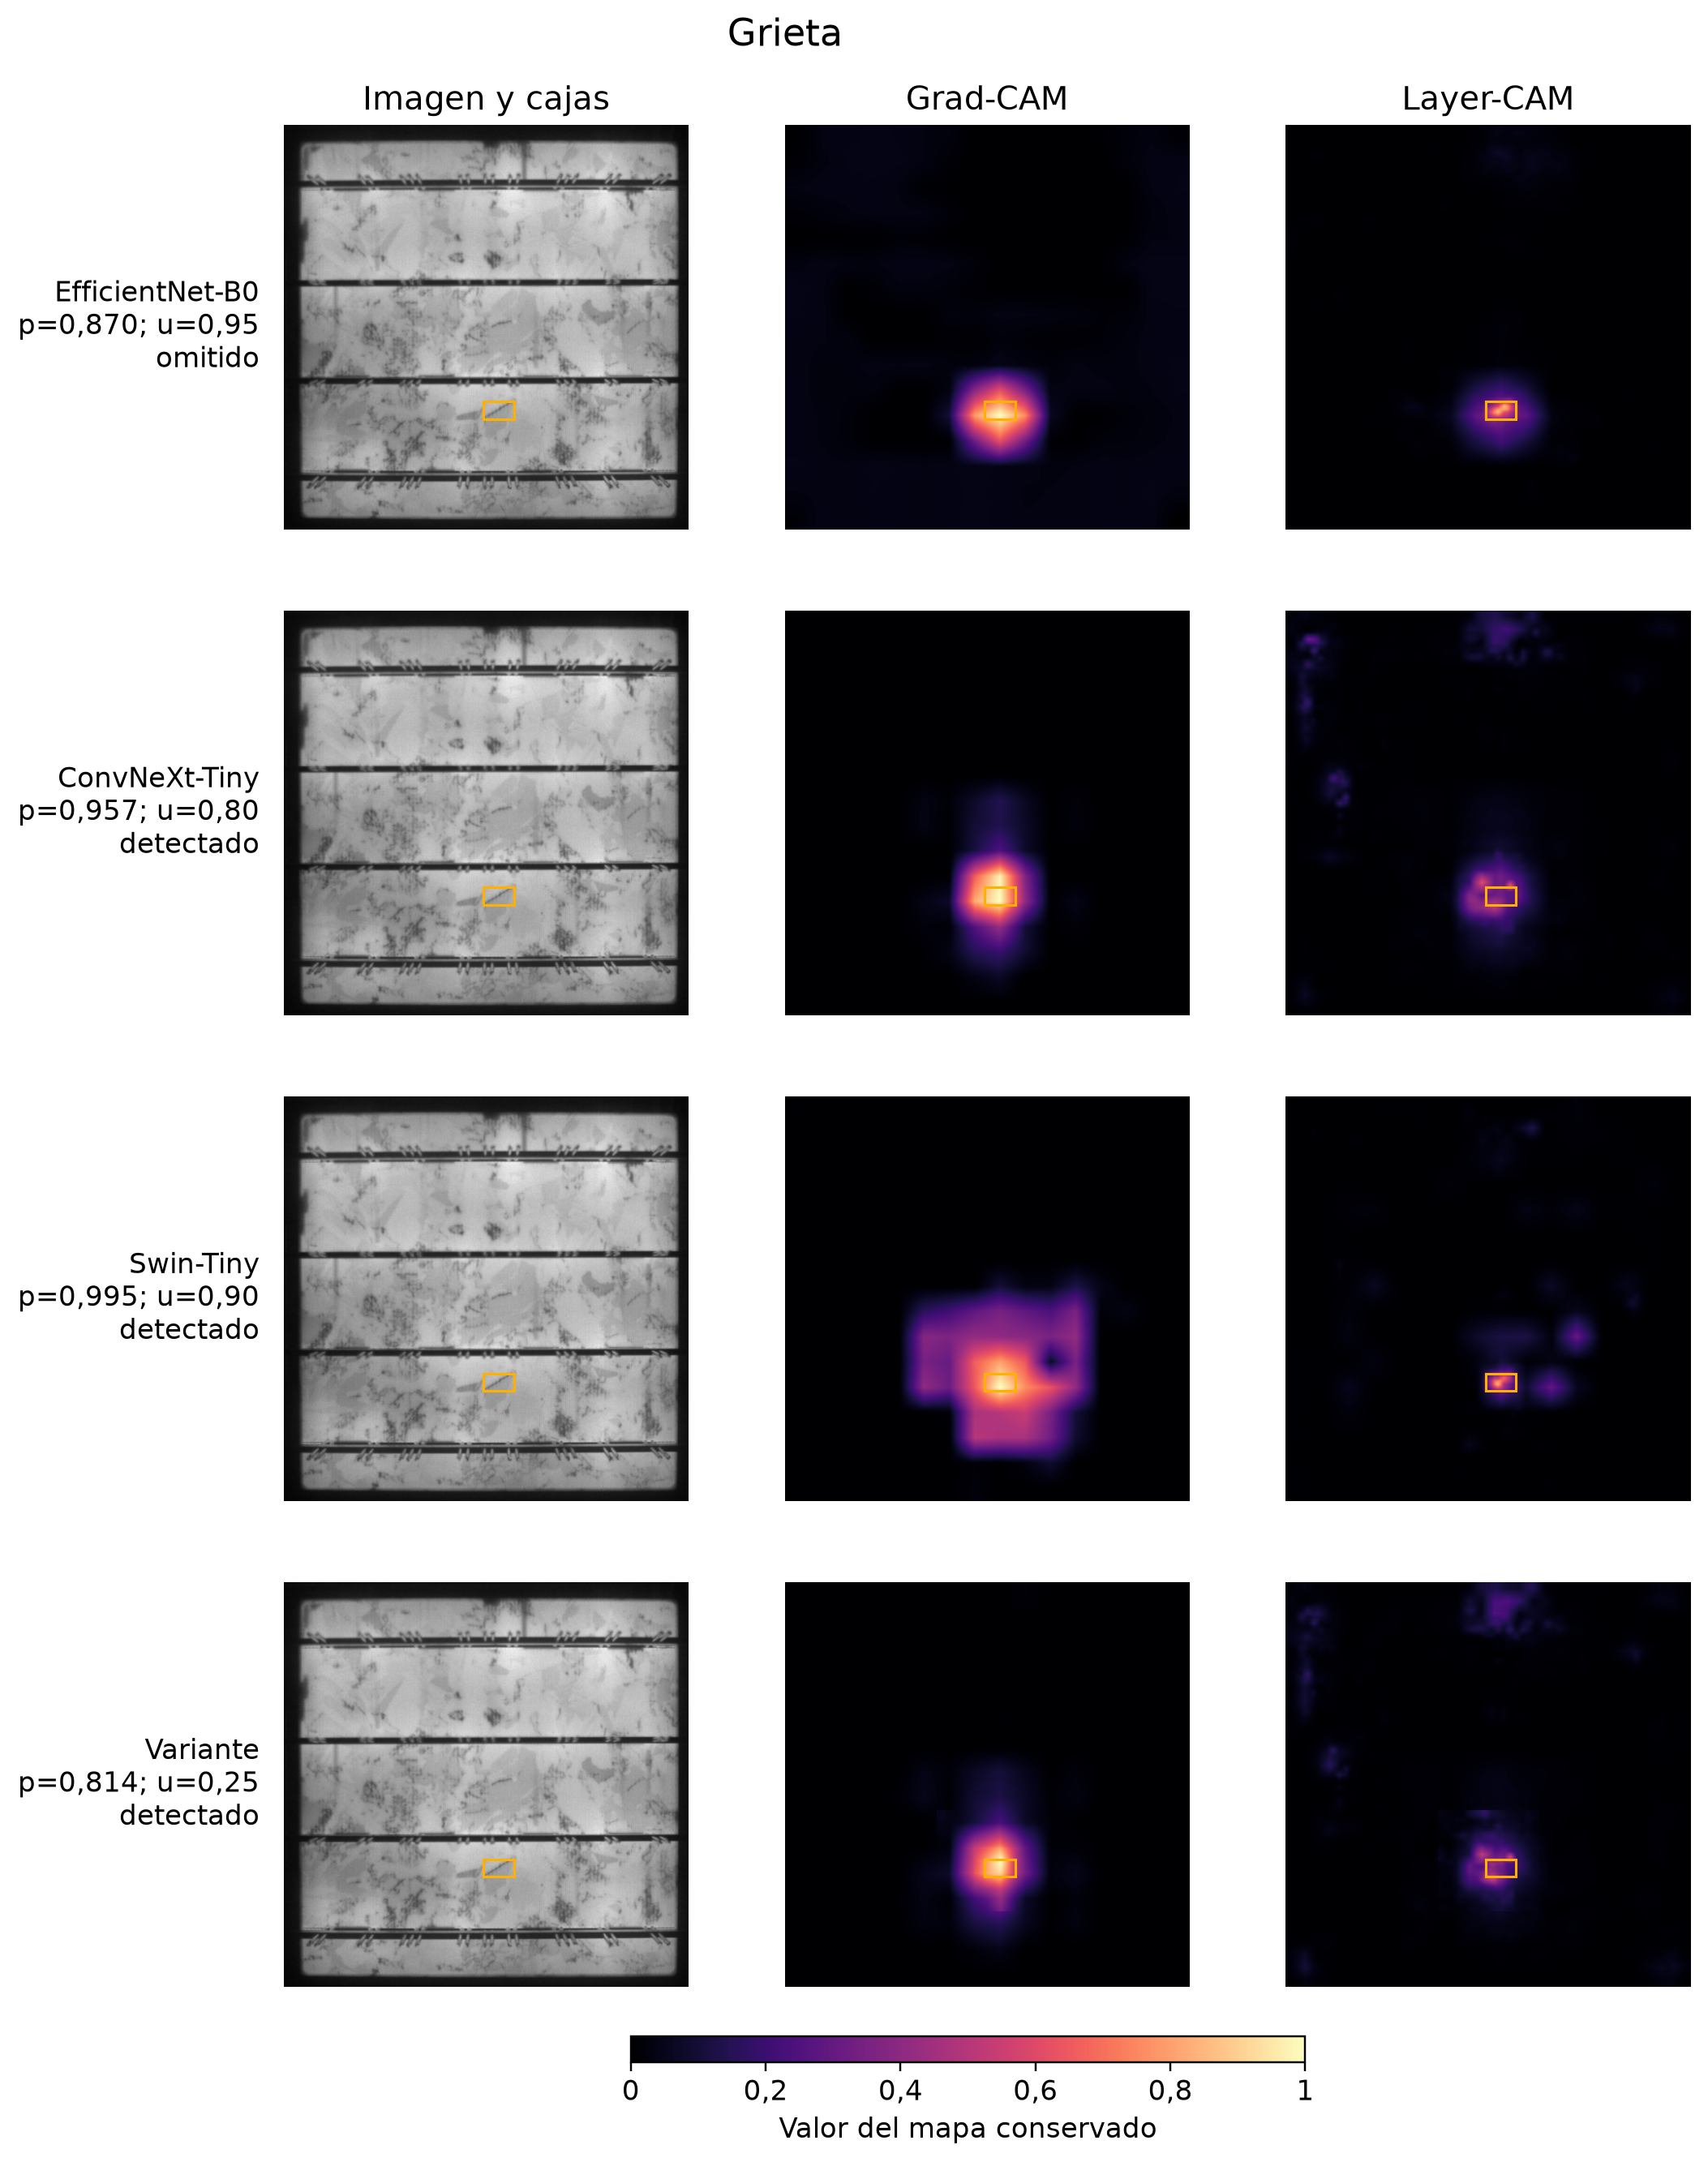

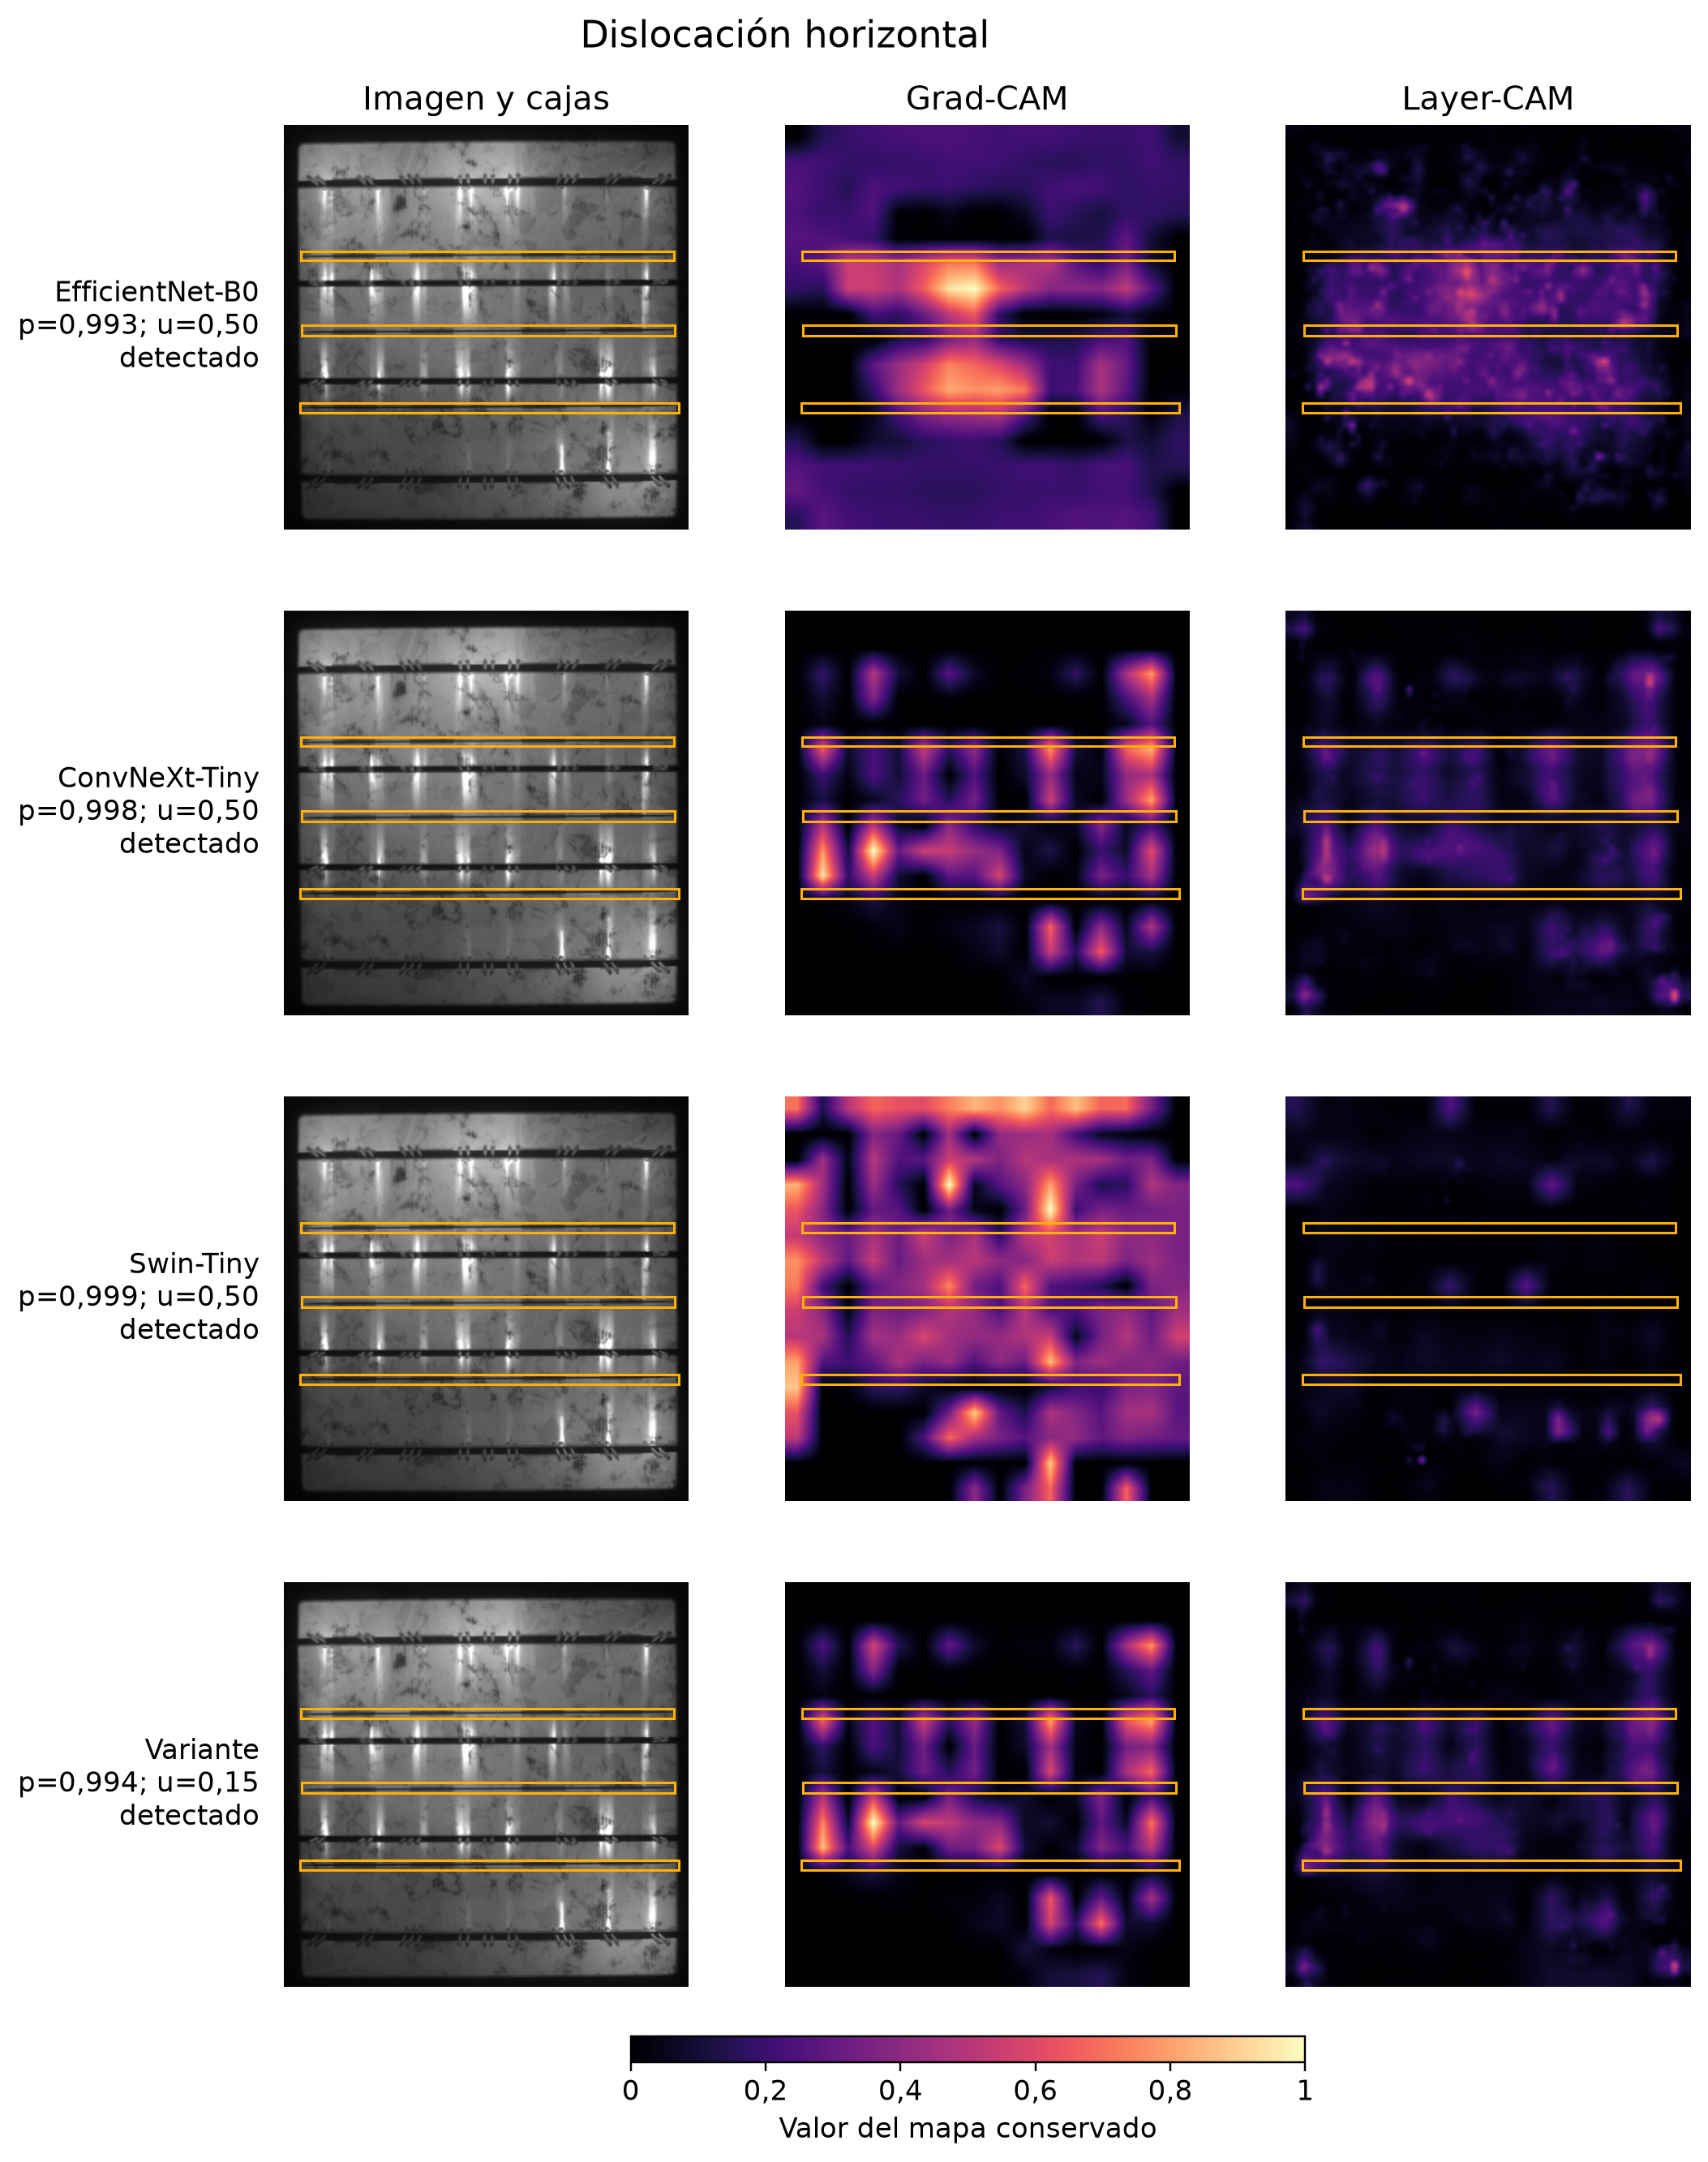

In [9]:
cases = [
    (
        next(identifier for identifier in selection["ids"] if by_id[identifier]["labels"][0]),
        "crack",
        "Grieta",
    ),
    (
        "sha_694f6521da51c19ccddf8ed02f6e13e17ad4d17042c8976dec0135e2c997b05d",
        "horizontal_dislocation",
        "Dislocación horizontal",
    ),
]
for identifier, defect, title in cases:
    record, c = by_id[identifier], CLASS_NAMES.index(defect)
    assert identifier in control_ids and identifier in selection["ids"]
    with Image.open(PROJECT_ROOT / record["image_path"]) as image:
        background = np.asarray(letterbox(image.convert("L"), 512))
    width, height = record["width"], record["height"]
    rw, rh = round(width * 512 / max(width, height)), round(height * 512 / max(width, height))
    left, top = (512 - rw) // 2, (512 - rh) // 2
    valid = np.zeros((512, 512), dtype=bool)
    valid[top : top + rh, left : left + rw] = True
    boxes = [
        (
            left + b["xmin"] * rw / width,
            top + b["ymin"] * rh / height,
            (b["xmax"] - b["xmin"]) * rw / width,
            (b["ymax"] - b["ymin"]) * rh / height,
        )
        for b in record["boxes"]
        if b["class_name"] == defect
    ]
    report = json.loads((XAI_DIR / f"{identifier}.json").read_text())
    probability = next(row["probability"] for row in report["spatial"] if row["class"] == defect)
    if read_xai_result(XAI_DIR / f"{identifier}.json", identity, maps=True) is None:
        raise ValueError(f"Faltan mapas para {identifier}")
    with np.load(XAI_DIR / f"{identifier}.npz", allow_pickle=False) as archive:
        variant_maps = {method: archive[f"{method}_{c}"] for method in methods}
    fig, axes = plt.subplots(4, 3, figsize=(10.8, 12))
    for row, (name, label) in enumerate(zip(model_names, model_titles, strict=True)):
        p = (
            probability
            if name == "variant"
            else reference_probabilities[name].loc[(identifier, defect), "probability"]
        )
        threshold = (
            thresholds[c] if name == "variant" else reference_runs[name]["metrics"]["thresholds"][c]
        )
        decision = "detectado" if p >= threshold else "omitido"
        axes[row, 0].text(
            -0.06,
            0.5,
            label + f"\np={p:.3f}; u={threshold:.2f}\n".replace(".", ",") + decision,
            transform=axes[row, 0].transAxes,
            ha="right",
            va="center",
            fontsize=11,
        )
        for column, method in enumerate([None, "gradcam", "layercam"]):
            axis = axes[row, column]
            if method is None:
                axis.imshow(background, cmap="gray", vmin=0, vmax=255)
            else:
                values = (
                    variant_maps[method]
                    if name == "variant"
                    else reference_maps[name][identifier, c, method].numpy()
                )
                rendered = axis.imshow(
                    np.ma.masked_where(~valid, values), cmap="magma", vmin=0, vmax=1
                )
            for x, y, w, h in boxes:
                axis.add_patch(
                    Rectangle((x, y), w, h, fill=False, edgecolor="#ffb000", linewidth=1)
                )
            if row == 0:
                axis.set_title(["Imagen y cajas", "Grad-CAM", "Layer-CAM"][column])
            axis.axis("off")
    fig.suptitle(title, fontsize=15, y=0.99)
    fig.subplots_adjust(left=0.22, right=0.99, bottom=0.07, top=0.94, wspace=0.04, hspace=0.20)
    bar = fig.colorbar(
        rendered, cax=fig.add_axes([0.42, 0.035, 0.35, 0.012]), orientation="horizontal"
    )
    bar.set_label("Valor del mapa conservado")
    bar.ax.xaxis.set_major_formatter(FuncFormatter(decimal_label))
    show_figure(fig)
    if defect == "horizontal_dislocation":
        horizontal_case = (
            title,
            background,
            boxes,
            valid,
            variant_maps["rise"],
            probability,
            thresholds[c],
        )

En la grieta, los dos mapas de EfficientNet resaltan la zona anotada. Con una probabilidad de 0,870 y un umbral de 0,95, es el único modelo que omite la etiqueta.

En la dislocación horizontal, los cuatro modelos detectan el defecto con una probabilidad superior al 99 %. Los máximos de ambos mapas CAM quedan fuera de las franjas anotadas.

### Mapa RISE de la dislocación horizontal

Para la misma dislocación, mostramos los valores originales de RISE en la variante. La escala de color se ajusta al rango del mapa y la cruz cian señala el máximo.

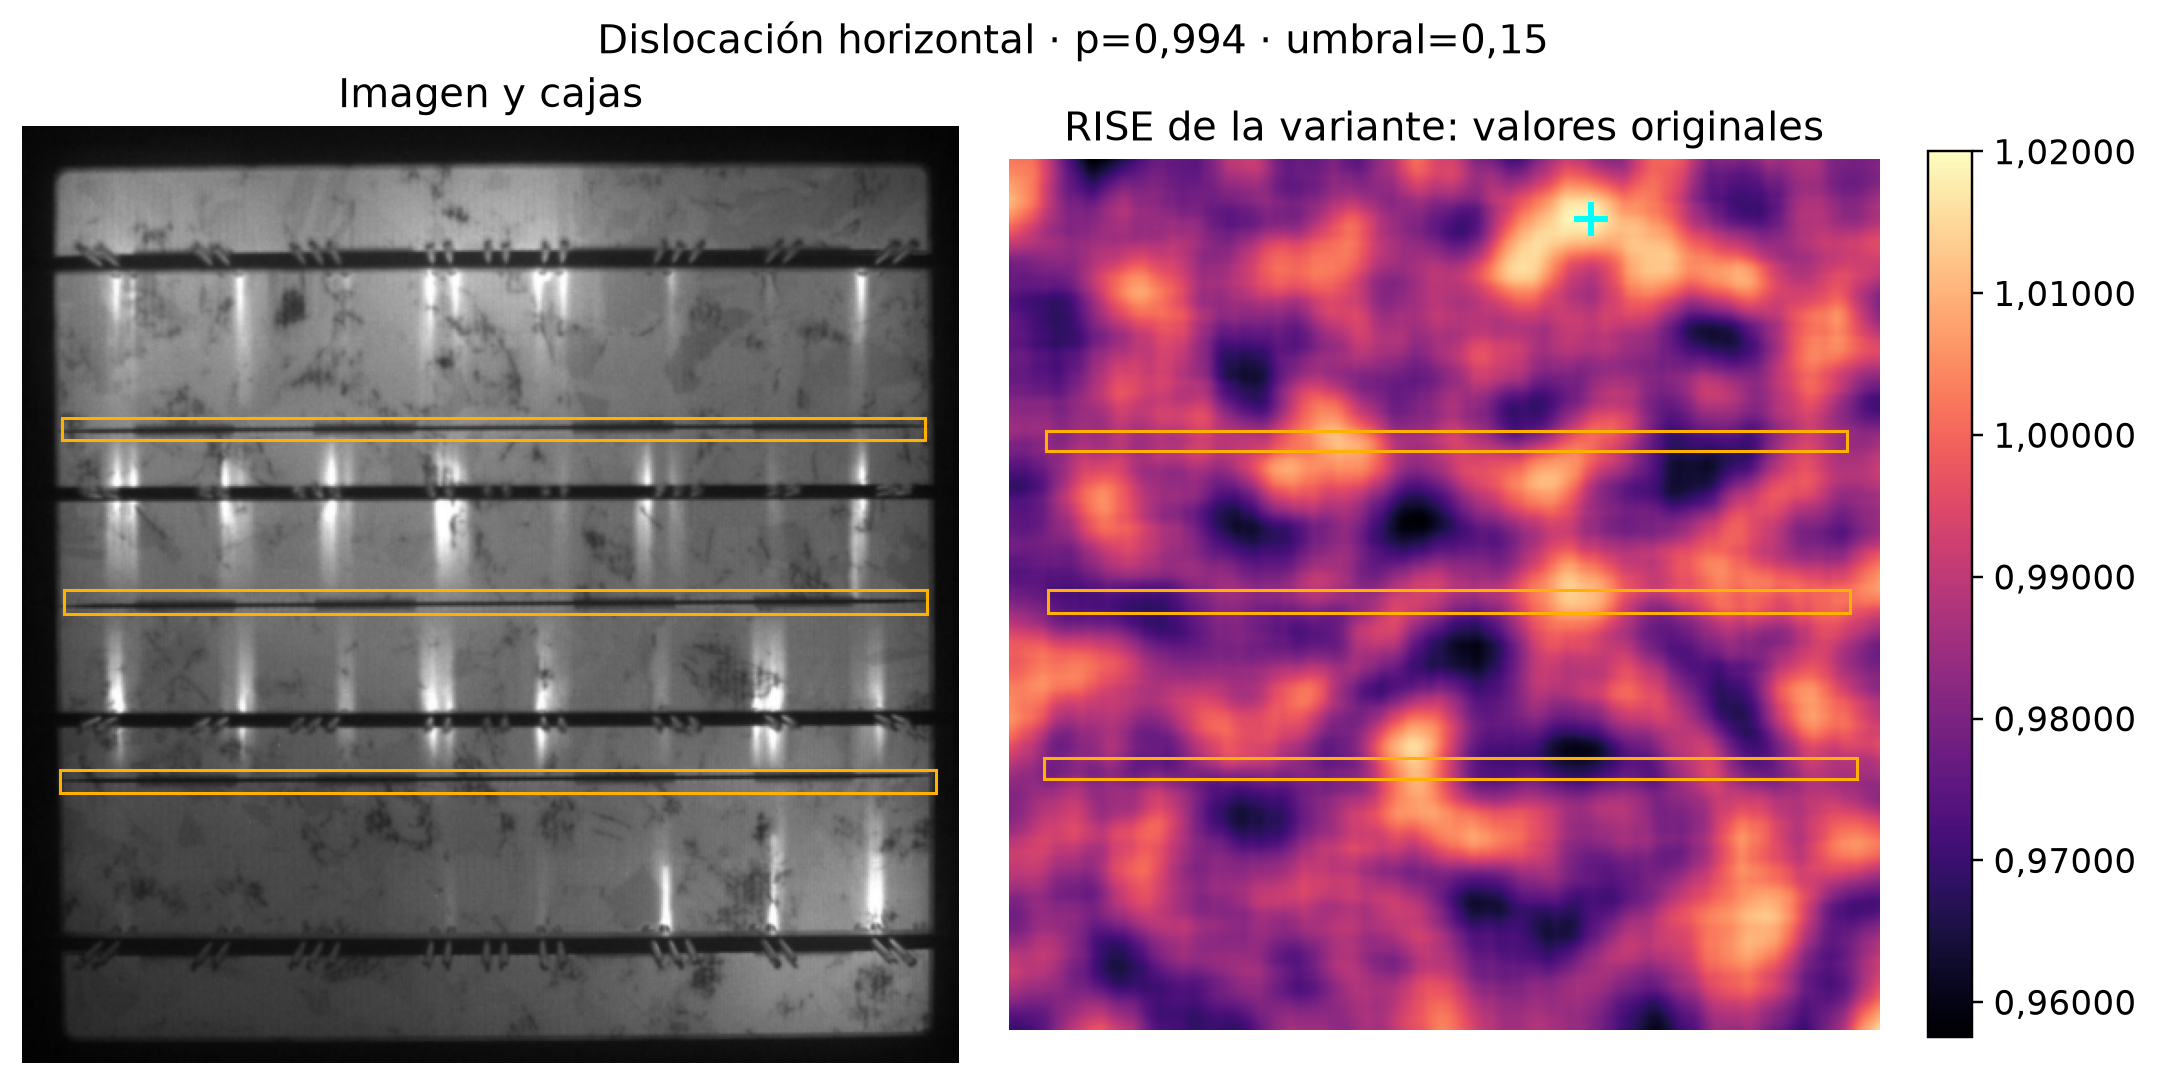

In [10]:
# Keep RISE's original, narrow value range explicit rather than rescaling its array.
title, background, boxes, valid, values, probability, threshold = horizontal_case
minimum, maximum = float(values[valid].min()), float(values[valid].max())
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(background, cmap="gray", vmin=0, vmax=255)
rendered = axes[1].imshow(
    np.ma.masked_where(~valid, values), cmap="magma", vmin=minimum, vmax=maximum
)
for axis in axes:
    for x, y, w, h in boxes:
        axis.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="#ffb000", linewidth=1))
    axis.axis("off")
maximum_y, maximum_x = np.unravel_index(np.argmax(np.where(valid, values, -np.inf)), values.shape)
axes[1].scatter(maximum_x, maximum_y, marker="+", color="cyan", s=120, linewidths=2)
axes[0].set_title("Imagen y cajas")
axes[1].set_title("RISE de la variante: valores originales")
bar = fig.colorbar(rendered, ax=axes[1], fraction=0.046)
bar.ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:.5f}".replace(".", ",")))
fig.suptitle(title + f" · p={probability:.3f} · umbral={threshold:.2f}".replace(".", ","))
fig.tight_layout()
show_figure(fig)

La barra de color va aproximadamente de 0,96 a 1,02. Las diferencias entre zonas son pequeñas y el máximo queda fuera de las cajas.

### Efecto de la imagen de reemplazo

Comparamos los mismos 16 pares de imagen y defecto, procedentes de 12 imágenes. Las referencias desenfocan su vista de 512 píxeles con un núcleo de 51 píxeles y sigma 12. La variante aplica un desenfoque proporcional al tamaño de la imagen original antes de preparar la vista global y los recortes.

#### ΔAUC medio por modelo, método y reemplazo

La tabla muestra el ΔAUC medio de la submuestra con dos reemplazos, la media de entrenamiento (`mean`) y la imagen desenfocada (`blur`).

In [11]:
replacement_rows = []
for name in model_names:
    if name == "variant":
        frame = pd.concat(
            [
                curves.loc[curves.id.isin(control_ids) & curves.method.isin(methods[:2])],
                variant_blur,
            ],
            ignore_index=True,
        )
        frame = frame.loc[~frame.healthy].copy()
        frame["baseline"] = frame.baseline.replace({"native_blur": "blur"})
        keys = ["id", "class", "baseline", "method", "random_order"]
        probability_column = "masked_probability"
    else:
        frame = reference_perturbations[name].loc[lambda rows: ~rows.healthy].copy()
        keys = ["id", "class", "baseline", "method"]
        probability_column = "probability"
    assert set(frame[["id", "class"]].itertuples(index=False, name=None)) == positive_pairs
    assert not frame.duplicated(keys + ["fraction"]).any()
    for _, group in frame.groupby(keys):
        group = group.sort_values("fraction")
        assert len(group) == 21 and np.allclose(group.fraction, np.linspace(0, 1, 21))
        assert np.isclose(
            np.trapezoid(group[probability_column], group.fraction),
            group.auc_probability.iloc[0],
            atol=1e-7,
            rtol=1e-6,
        )
    if name == "variant":
        areas = frame.groupby(keys).auc_probability.first().unstack("random_order")
        paired = (areas[False] - areas[True]).rename("delta_auc").reset_index()
    else:
        areas = frame.groupby(keys).auc_probability.first().unstack("method")
        paired = (
            areas[methods[:2]]
            .subtract(areas["random"], axis=0)
            .rename_axis(columns="method")
            .stack()
            .rename("delta_auc")
            .reset_index()
        )
    replacement_rows.append(paired.assign(model=name))
replacement_pairs = pd.concat(replacement_rows, ignore_index=True)
replacement_means = replacement_pairs.groupby(["model", "method", "baseline"]).delta_auc.agg(
    ["mean", "count"]
)
assert replacement_means["count"].eq(16).all()
display(replacement_means)

mean  count
model           method   baseline                 
convnext_tiny   gradcam  blur     -0.310206     16
                         mean     -0.270147     16
                layercam blur     -0.251161     16
                         mean     -0.258853     16
efficientnet_b0 gradcam  blur     -0.112340     16
                         mean      0.391512     16
                layercam blur     -0.135597     16
                         mean      0.300130     16
swin_t          gradcam  blur     -0.192077     16
                         mean     -0.205967     16
                layercam blur     -0.199593     16
                         mean     -0.201478     16
variant         gradcam  blur     -0.248174     16
                         mean     -0.225713     16
                layercam blur     -0.206196     16
                         mean     -0.227632     16

Con Grad-CAM de la variante, ΔAUC pasa de −0,226 con la media de entrenamiento a −0,248 con el desenfoque. Con Layer-CAM pasa de −0,228 a −0,206. El reemplazo cambia la diferencia en sentidos opuestos.

#### Media de entrenamiento frente a desenfoque

Cada panel representa las medias de la tabla para un método. Los círculos azules corresponden a la media de entrenamiento y los rombos naranjas al desenfoque. La línea vertical marca la igualdad con el orden aleatorio.

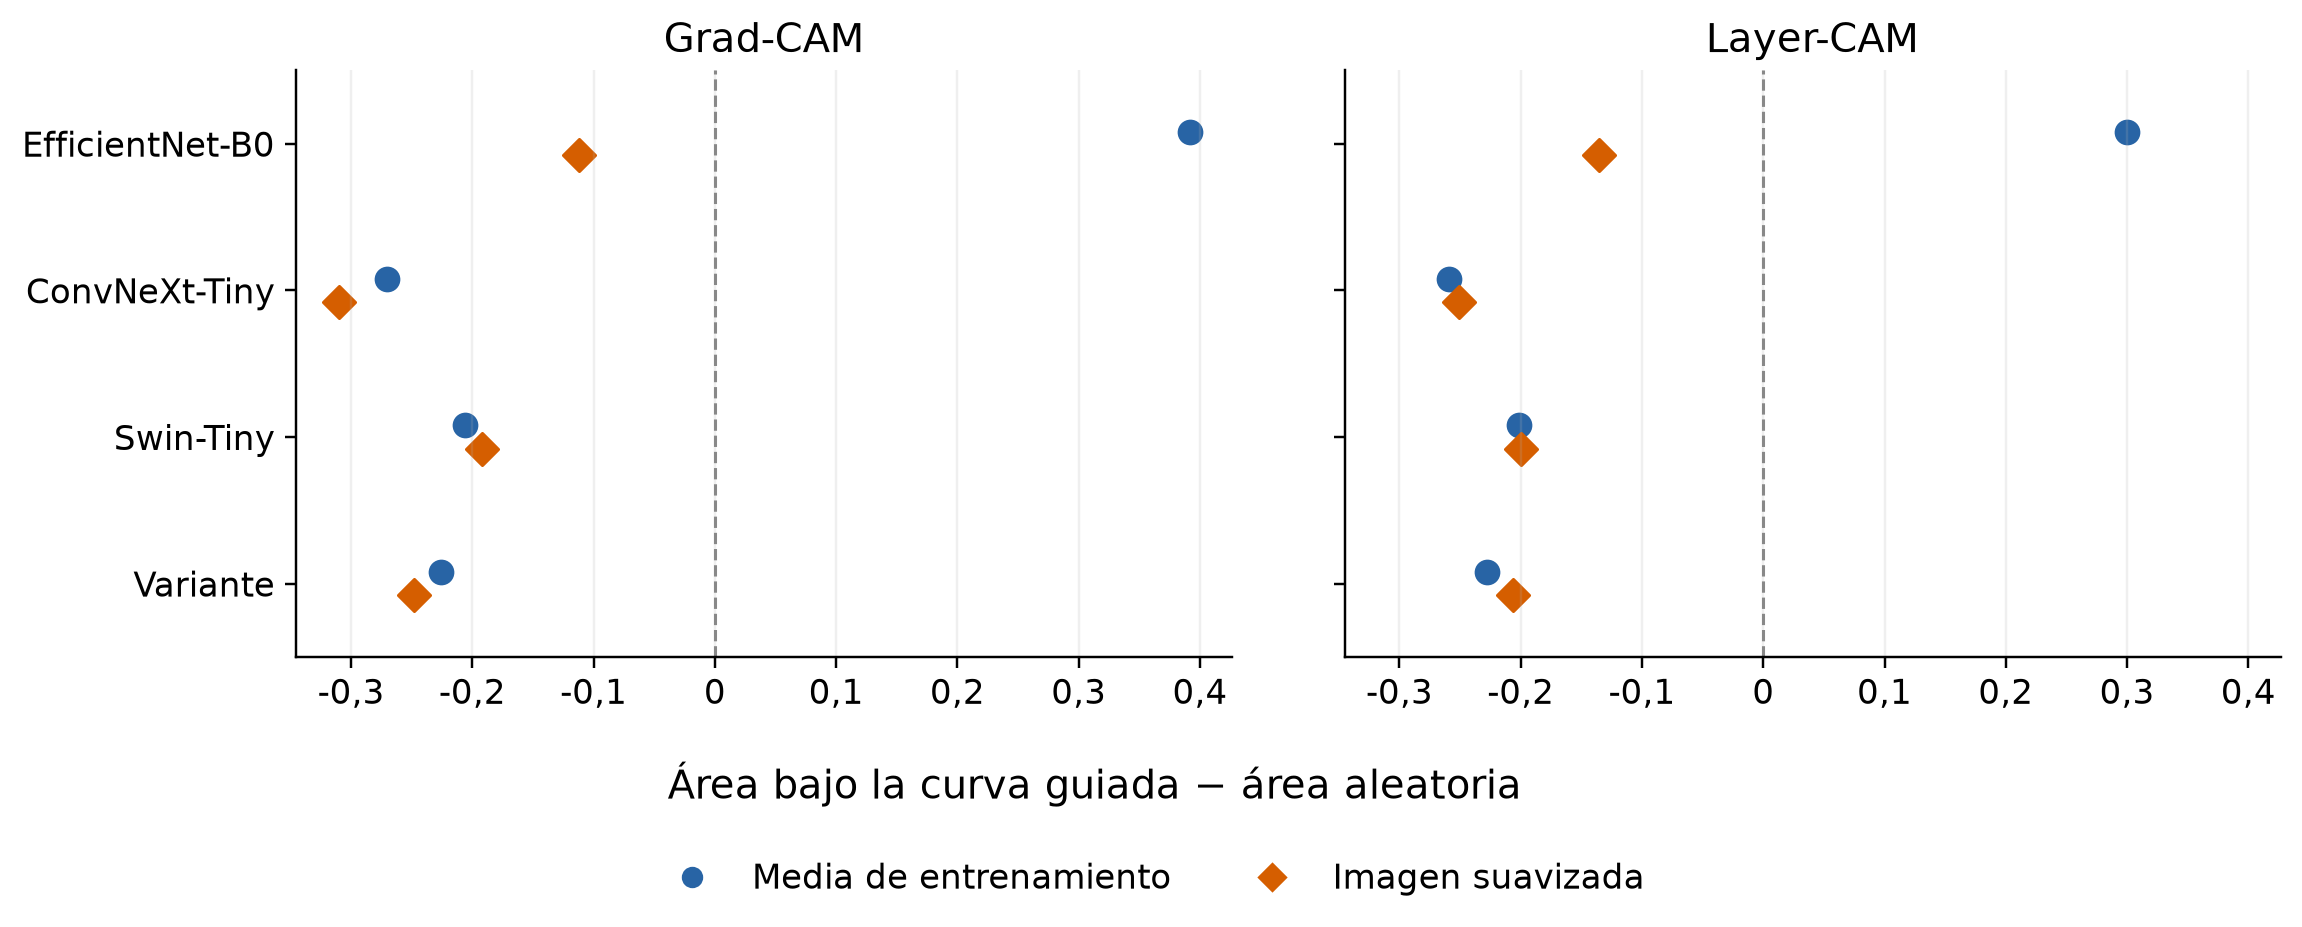

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
for axis, method, title in zip(axes, methods[:2], method_titles[:2], strict=True):
    axis.axvline(0, color="#888888", linestyle="--", linewidth=1)
    for y, name in enumerate(model_names):
        for baseline, color, offset, marker in [
            ("mean", "#2864a5", -0.08, "o"),
            ("blur", "#d55e00", 0.08, "D"),
        ]:
            value = replacement_means.loc[(name, method, baseline), "mean"]
            axis.scatter(value, y + offset, color=color, marker=marker, s=55)
    axis.set(title=title, yticks=range(4), yticklabels=model_titles, ylim=(3.5, -0.5))
    axis.xaxis.set_major_formatter(FuncFormatter(decimal_label))
    axis.grid(axis="x", alpha=0.2)
fig.supxlabel("Área bajo la curva guiada − área aleatoria", y=0.12)
fig.legend(
    handles=[
        Line2D([], [], color="#2864a5", marker="o", linestyle="", label="Media de entrenamiento"),
        Line2D([], [], color="#d55e00", marker="D", linestyle="", label="Imagen suavizada"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
)
fig.subplots_adjust(left=0.17, right=0.99, bottom=0.28, top=0.90, wspace=0.12)
show_figure(fig)

En EfficientNet, los dos métodos pasan de un ΔAUC positivo con la media a uno negativo con el desenfoque. ConvNeXt, Swin y la variante mantienen un área guiada menor que la aleatoria con los dos reemplazos.

### Sensibilidad de los mapas a los pesos

Sobre los mismos 16 pares comprobamos cuánto cambia el mapa en dos controles. En la variante, reinicializamos el clasificador global y las salidas de la fusión en un control, y los extractores de ambas ramas en el otro.

#### Correlación por modelo, método y semilla

La tabla promedia las correlaciones de Pearson con el mapa entrenado para cada modelo, parte reinicializada, método y semilla. `count` indica cuántos pares contribuyen a la media.

In [13]:
control_frames = []
for name in model_names:
    frame = controls if name == "variant" else reference_controls[name]
    frame = frame.loc[~frame.healthy].copy()
    scope_map = (
        {"readouts": "outputs", "encoders": "extractors"}
        if name == "variant"
        else {"head": "outputs", "backbone": "extractors"}
    )
    assert set(frame.method) == set(methods[:2]) and set(frame.seed) == {43, 44}
    assert set(frame.scope) == set(scope_map)
    for _, group in frame.groupby(["scope", "seed", "method"]):
        assert len(group) == 16
        assert set(group[["id", "class"]].itertuples(index=False, name=None)) == positive_pairs
    control_frames.append(frame.assign(model=name, panel=frame.scope.map(scope_map)))
control_pairs = pd.concat(control_frames, ignore_index=True)
control_means = control_pairs.groupby(["model", "panel", "method", "seed"]).correlation.agg(
    ["mean", "count"]
)
assert len(control_means) == 32 and control_means["count"].eq(16).all()
display(control_means)

mean  count
model           panel      method   seed                 
convnext_tiny   extractors gradcam  43    0.013667     16
                                    44   -0.044224     16
                           layercam 43    0.002958     16
                                    44   -0.012890     16
                outputs    gradcam  43    0.027356     16
                                    44    0.218263     16
                           layercam 43    0.420401     16
                                    44    0.547542     16
efficientnet_b0 extractors gradcam  43    0.022624     16
                                    44    0.005768     16
                           layercam 43    0.082844     16
                                    44   -0.075544     16
                outputs    gradcam  43    0.256508     16
                                    44    0.411012     16
                           layercam 43    0.772628     16
                                    44    0.794739     16
swin_t          extractors gradcam  43   -0.003914     16
                                    44    0.050672     16
                           layercam 43   -0.027330     16
                                    44   -0.069410     16
                outputs    gradcam  43    0.004948     16
                                    44   -0.268380     16
                           layercam 43    0.470780     16
                                    44    0.200584     16
variant         extractors gradcam  43    0.004544     16
                                    44   -0.064264     16
                           layercam 43   -0.001756     16
                                    44   -0.066108     16
                outputs    gradcam  43    0.301992     16
                                    44    0.159126     16
                           layercam 43    0.572985     16
                                    44    0.562696     16

Para Layer-CAM en la variante, las correlaciones medias al reinicializar las salidas son 0,573 y 0,563 con las semillas 43 y 44. Al reinicializar los extractores, quedan en −0,002 y −0,066.

#### Reinicialización de salidas y extractores

El panel superior muestra el efecto de reinicializar las salidas y el inferior, el de reinicializar los extractores. Los círculos corresponden a la semilla 43 y los rombos a la 44.

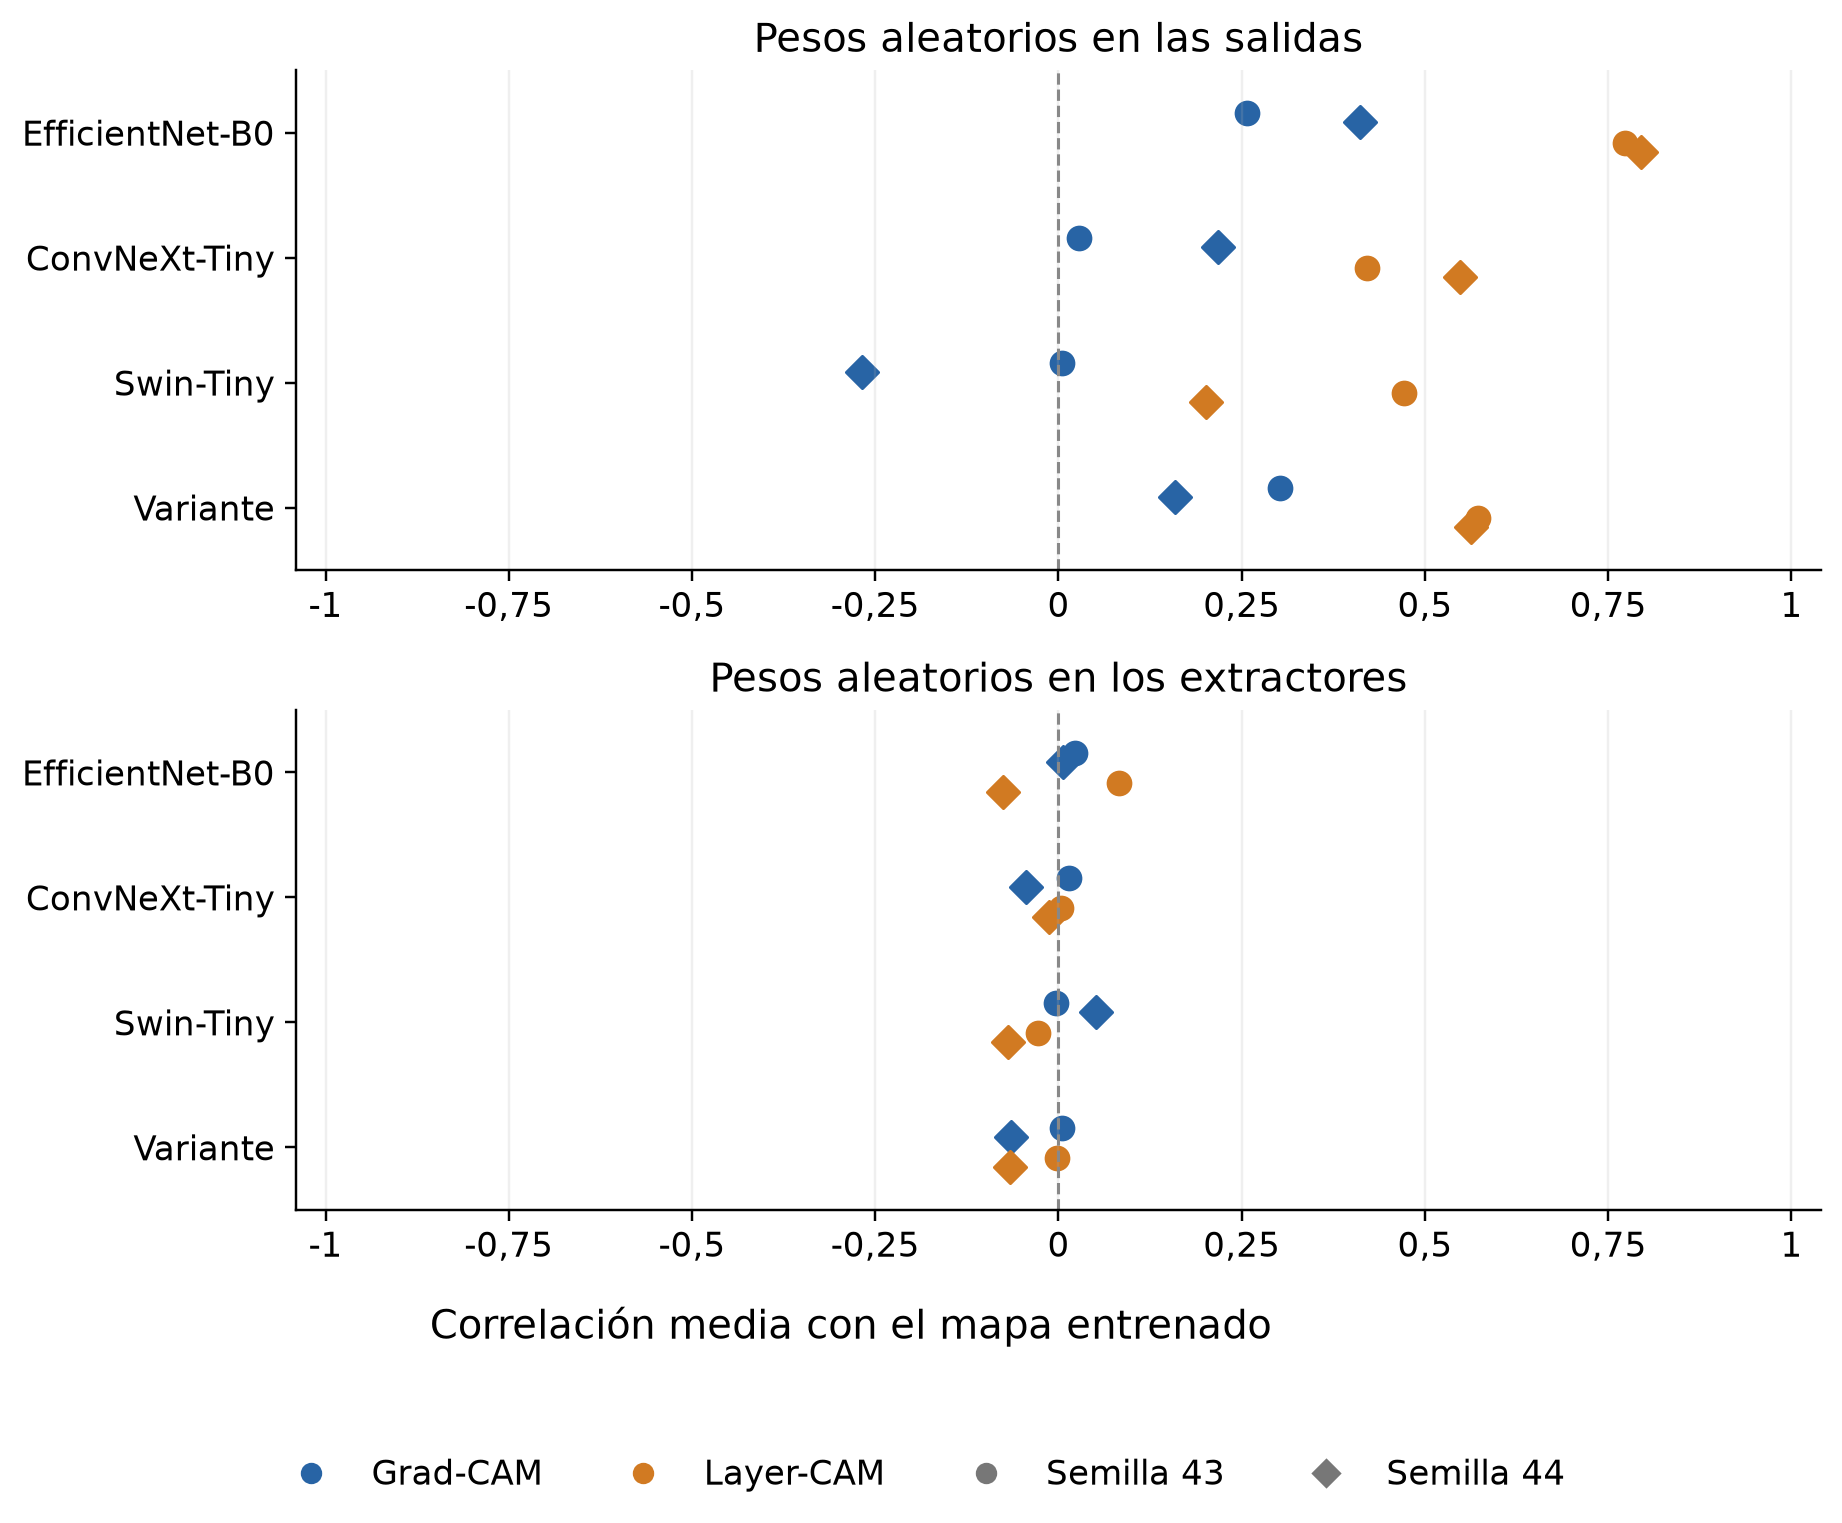

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, sharey=True)
for axis, panel, title in zip(
    axes,
    ["outputs", "extractors"],
    ["Pesos aleatorios en las salidas", "Pesos aleatorios en los extractores"],
    strict=True,
):
    axis.axvline(0, color="#888888", linestyle="--", linewidth=1)
    for y, name in enumerate(model_names):
        for method, color, offset in [("gradcam", "#2864a5", -0.12), ("layercam", "#d17a22", 0.12)]:
            for seed, marker, seed_offset in [(43, "o", -0.035), (44, "D", 0.035)]:
                value = control_means.loc[(name, panel, method, seed), "mean"]
                axis.scatter(value, y + offset + seed_offset, color=color, marker=marker, s=55)
    axis.set(
        title=title, xlim=(-1.04, 1.04), ylim=(3.5, -0.5), yticks=range(4), yticklabels=model_titles
    )
    axis.tick_params(labelbottom=True)
    axis.xaxis.set_major_formatter(FuncFormatter(decimal_label))
    axis.grid(axis="x", alpha=0.2)
fig.supxlabel("Correlación media con el mapa entrenado", y=0.11)
fig.legend(
    handles=[
        Line2D([], [], color="#2864a5", marker="o", linestyle="", label="Grad-CAM"),
        Line2D([], [], color="#d17a22", marker="o", linestyle="", label="Layer-CAM"),
        Line2D([], [], color="#777777", marker="o", linestyle="", label="Semilla 43"),
        Line2D([], [], color="#777777", marker="D", linestyle="", label="Semilla 44"),
    ],
    loc="lower center",
    ncol=4,
    frameon=False,
)
fig.subplots_adjust(left=0.22, right=0.99, bottom=0.20, top=0.94, hspace=0.28)
show_figure(fig)

Al reinicializar los extractores, las correlaciones se agrupan cerca de cero en los cuatro modelos. Al reinicializar las salidas, Layer-CAM conserva más parecido con el mapa entrenado que Grad-CAM en ambas semillas.

Con ambos métodos CAM, los mapas de la variante coinciden más con las cajas que los de ConvNeXt. Con la media de entrenamiento como reemplazo, la ventaja del borrado guiado frente al aleatorio es mayor en ConvNeXt.

## Exportar los modelos

Guardamos los pesos de los modelos en `outputs/models/`, junto con los umbrales y los ajustes de preprocesado necesarios para reutilizarlos.

In [15]:
from photovoltaic_xai.variant import export_models

export_path = export_models(PROJECT_ROOT, prepared)
print("Modelos exportados en", export_path.relative_to(PROJECT_ROOT))

Modelos exportados en outputs/models
